# F5 · Searching across platforms and within a section (Fig 5)

**Run first:** `experiments/compute/R5_cross_platform.ipynb` (writes `results/cross_platform/`) and
`experiments/compute/R6_breast_programs.ipynb` (writes `results/breast_programs/`).

Panels (each saved to `figures/fig5_cross_platform/panels/`, then the full figure):
* **A** the two breast sections (Xenium, Visium), cells / spots coloured by coarse class, with tile boxes. The example
  query is outlined in magenta (Visium) and its top 5 in black (Xenium; co-located tile dashed). (Old Fig 5A.)
* **B** the Visium query and its top 5 Xenium tiles (the co-located one dashed) (Spindle-naive with the global shift, seed 0), with the share of
  the query's dominant class in each. (Old Fig 5E.)
* **C** a held-out breast tile (Xenium, seed 0), Spindle-naive's top 5, and the cell-type composition of the query,
  the top 5 (cells pooled), 10 random index tiles and the section. (Old Fig 6D, top 5 of 10; the composition-difference
  strip is appendix material.) Classes in the colours of A where they correspond (immune split into T, B, myeloid).

Old Fig 5B–D and Fig 6A–C, E: `experiments/figures/_backup_2026-11-01/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle

import style as ps
from sections import CLASSES

FIG = "fig5_cross_platform"
RES = ps.ROOT / "results" / "cross_platform"
S0 = ps.ROOT / "results" / "breast_programs" / "seed0"
CLASS_COLORS = {"Invasive tumour": "#CC6677", "DCIS": "#882255", "Myoepithelial": "#DDCC77", "Stroma": "#44AA99",
                "Immune": "#332288", "Adipocytes": "#E69F00", "Mixed": "#AAAAAA"}
# C's finer classes (sections.CLASSES order) in A's colours; immune split into three blues
BREAST_COLORS = {"Invasive tumour": "#CC6677", "DCIS": "#882255", "Myoepithelial": "#DDCC77", "Stromal": "#44AA99",
                 "Endothelial / perivascular": "#117733", "Myeloid": "#88CCEE", "T cells": "#332288",
                 "B cells": "#6699CC"}
BREAST_NAMES = [n for n, _, _ in CLASSES]
assert set(BREAST_NAMES) == set(BREAST_COLORS), BREAST_NAMES
BREAST_PALETTE = np.array([BREAST_COLORS[n] for n in BREAST_NAMES])
NAIVE = ps.TIER_COLORS["naive"]
SPOT_UM = 55.0
N_CROSS, N_BREAST = 5, 5  # hits shown in B and C

cells = np.load(RES / "cells.npz")
classes = list(cells["classes"])
tiles = pd.read_csv(RES / "tiles.csv")
example = pd.read_csv(RES / "example.csv").sort_values("rank")
VIS = tiles[tiles.platform == "Visium"].set_index("tile")
XEN = tiles[tiles.platform == "Xenium"].set_index("tile")
X0, Y0 = tiles[["x0", "y0"]].min()
X1, Y1 = tiles[["x1", "y1"]].max()

H = 56.0                                   # panel height (mm), legends in a strip underneath
LEG_H = 10.0
MAP_X, MAP_W, MAP_GAP, MAP_TOP = 3.0, 30.0, 2.0, 5.0
MAP_H = MAP_W * (Y1 - Y0) / (X1 - X0)
W_A = MAP_X + 2 * MAP_W + MAP_GAP
W_B, W_C = 46.0, 180.0 - W_A - 46.0 - 3.0
print(f"map {MAP_W:.0f} x {MAP_H:.1f} mm; widths A {W_A:.0f}, B {W_B:.0f}, C {W_C:.0f}")


def mm_axes(fig, x, y, w, h):
    """Axes of the w x h mm box at (x, y) mm from the panel's top-left corner."""
    W, H_ = ps.size_mm(fig)
    return ps.axes(fig, left=x, top=y, right=W - x - w, bottom=H_ - y - h)


def mm_text(fig, x, y, s, ha="left", **kw):
    """Text with its top at (x, y) mm from the panel's top-left corner."""
    W, H_ = ps.size_mm(fig)
    fig.text(x / W, 1 - y / H_, s, ha=ha, va="top", fontsize=kw.pop("size", ps.TICK_PT), **kw)


def points(platform, sel=None):
    xy, cl = cells[f"{platform}_xy"], cells[f"{platform}_class"]
    if sel is not None:
        xy, cl = xy[sel], cl[sel]
    return xy, np.array([CLASS_COLORS[classes[c]] for c in cl])


def spot_size(w_mm, w_um):
    """Marker area (pt^2) of a SPOT_UM-wide spot on an axes w_mm wide showing w_um."""
    return (SPOT_UM / w_um * w_mm / 25.4 * 72) ** 2


def box(ax, r, color, ls="-", lw=0.75):
    ax.add_patch(Rectangle((r.x0, r.y0), r.x1 - r.x0, r.y1 - r.y0, fill=False, ec=color, lw=lw, ls=ls, zorder=5))


def spatial(ax, x0, x1, y0, y1):
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # image orientation
    ax.set_aspect("equal")
    ax.axis("off")


def square(ax, x0, y0, x1, y1, pad=1.06):
    side = max(x1 - x0, y1 - y0) * pad
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    spatial(ax, cx - side / 2, cx + side / 2, cy - side / 2, cy + side / 2)
    return side

map 30 x 40.8 mm; widths A 65, B 46, C 66


## A · the two sections

figures/fig5_cross_platform/panels/A.pdf/.png: 65 x 56 mm, 0.8 / 0.9 MB


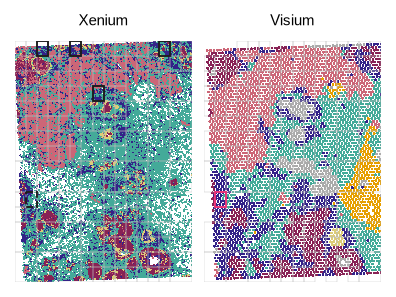

In [2]:
def panel_a(fig):
    shown = example[example["rank"] <= N_CROSS]
    for j, platform in enumerate(("Xenium", "Visium")):
        ax = mm_axes(fig, MAP_X + j * (MAP_W + MAP_GAP), MAP_TOP, MAP_W, MAP_H)
        xy, col = points(platform)
        s = 0.05 if platform == "Xenium" else spot_size(MAP_W, X1 - X0)
        ax.scatter(xy[:, 0], xy[:, 1], s=s, c=col, lw=0, rasterized=True, antialiased=False)
        for r in tiles[tiles.platform == platform].itertuples():
            box(ax, r, "#BDBDBD", lw=0.2)
        if platform == "Visium":
            box(ax, VIS.loc[int(example["query"].iloc[0])], ps.QUERY_COLOR, lw=0.9)
        else:
            for r in shown.itertuples():
                box(ax, XEN.loc[r.index_tile], ps.INK, ls="--" if r.matched else "-", lw=0.9)
        spatial(ax, X0, X1, Y0, Y1)
        mm_text(fig, MAP_X + j * (MAP_W + MAP_GAP) + MAP_W / 2, 0.5, platform, ha="center", size=ps.LABEL_PT)


fig = ps.panel(W_A, H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")
plt.show()

## B · the Visium query and its top 5 Xenium tiles

figures/fig5_cross_platform/panels/B.pdf/.png: 46 x 56 mm, 0.2 / 0.3 MB


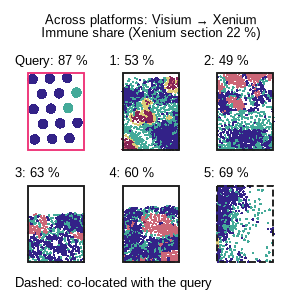

In [3]:
TW, B_TOP, B_ROW, B_GAP = 14.0, 10.0, 19.0, 2.0  # tile width, first row top, row step, column gap (mm)


def zoom(fig, x, y, platform, r, color, label, ls="-"):
    ax = mm_axes(fig, x, y, TW, TW)
    xy = cells[f"{platform}_xy"]
    sel = np.flatnonzero((xy[:, 0] >= r.x0) & (xy[:, 0] < r.x1) & (xy[:, 1] >= r.y0) & (xy[:, 1] < r.y1))
    xy, col = points(platform, sel)
    side = max(r.x1 - r.x0, r.y1 - r.y0) * 1.08
    s = 0.6 if platform == "Xenium" else spot_size(TW, side)
    ax.scatter(xy[:, 0], xy[:, 1], s=s, c=col, lw=0, rasterized=True, antialiased=False)
    box(ax, r, color, ls=ls, lw=0.9)
    square(ax, r.x0, r.y0, r.x1, r.y1, pad=1.08)
    mm_text(fig, x, y - 2.6, label)


def panel_b(fig):
    e = example
    cls = e["focal_class"].iloc[0].lower()
    mm_text(fig, W_B / 2, 0.5, f"Across platforms: Visium → Xenium\n{cls.capitalize()} share (Xenium section "
            f"{100 * e['section_share'].iloc[0]:.0f} %)", ha="center", linespacing=1.1)
    pos = [(c * (TW + B_GAP), B_TOP + r * B_ROW) for r in range(2) for c in range(3)]
    zoom(fig, *pos[0], "Visium", VIS.loc[int(e["query"].iloc[0])], ps.QUERY_COLOR,
         f"Query: {100 * e['query_share'].iloc[0]:.0f} %")
    for r in e[e["rank"] <= N_CROSS].itertuples():
        zoom(fig, *pos[r.rank], "Xenium", XEN.loc[r.index_tile], ps.INK, f"{r.rank}: {100 * r.hit_share:.0f} %",
             ls="--" if r.matched else "-")
    mm_text(fig, 0.0, B_TOP + 2 * B_ROW - 3.0, "Dashed: co-located with the query")


fig = ps.panel(W_B, H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")
plt.show()

## C · a held-out breast tile, Spindle-naive's top 5, and their cell types

figures/fig5_cross_platform/panels/C.pdf/.png: 66 x 56 mm, 0.2 / 0.5 MB


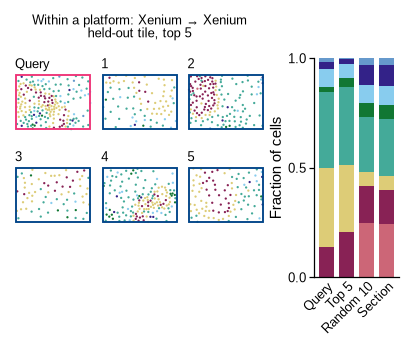

In [4]:
CT, C_TOP, C_GAP = 13.0, 10.5, 1.6  # tile width, first row top, column gap (mm)
bz = np.load(S0 / "example_cells.npz")
bex = pd.read_csv(S0 / "example.csv").set_index("set")
CH = CT * 0.75                                   # tile height: the tiles are 0.73 as high as wide
C_ROW = CH + 6.0
counts = [np.bincount(bz[f"cls{k}"], minlength=len(BREAST_NAMES)) for k in range(len(bz["tiles"]))]
pooled10 = sum(counts[1:11]) / sum(counts[1:11]).sum()
assert np.allclose(pooled10, bex.loc["top10", BREAST_NAMES].to_numpy(float)), "top-10 pooling differs from example.csv"
top5 = sum(counts[1:N_BREAST + 1]) / sum(counts[1:N_BREAST + 1]).sum()


def panel_c(fig):
    mm_text(fig, 3 * CT / 2 + C_GAP, 0.5, f"Within a platform: Xenium → Xenium\nheld-out tile, top {N_BREAST}",
            ha="center", linespacing=1.1)
    pos = [(c * (CT + C_GAP), C_TOP + r * C_ROW) for r in range(2) for c in range(3)]
    for k in range(N_BREAST + 1):
        x, y = pos[k]
        ax = mm_axes(fig, x, y, CT, CH)
        ax.scatter(*bz[f"xy{k}"].T, s=1.2, c=BREAST_PALETTE[bz[f"cls{k}"]], lw=0, rasterized=True)
        x0, y0, x1, y1 = bz[f"bbox{k}"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=0.9,
                               ec=ps.QUERY_COLOR if k == 0 else NAIVE))
        side_x = (x1 - x0) * 1.04
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        spatial(ax, cx - side_x / 2, cx + side_x / 2, cy - side_x * CH / CT / 2, cy + side_x * CH / CT / 2)
        mm_text(fig, x, y - 2.6, "Query" if k == 0 else str(k))

    sets = [("Query", bex.loc["query", BREAST_NAMES]), (f"Top {N_BREAST}", top5),
            ("Random 10", bex.loc["random10", BREAST_NAMES]), ("Section", bex.loc["section", BREAST_NAMES])]
    bx = 3 * CT + 2 * C_GAP
    ax = ps.axes(fig, left=bx + 8.5, right=1.0, top=C_TOP - 2.6, bottom=11.0)
    for i, (_, v) in enumerate(sets):
        v = np.asarray(v, float)
        ax.bar(i, v, 0.75, bottom=np.r_[0, np.cumsum(v)[:-1]], color=BREAST_PALETTE, lw=0)
    ax.set_xticks(range(len(sets)))
    ax.set_xticklabels([l for l, _ in sets], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.6, len(sets) - 0.4)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel("Fraction of cells")


fig = ps.panel(W_C, H)
panel_c(fig)
ps.save_panel(fig, FIG, "C")
plt.show()

## Legends and full figure

figures/fig5_cross_platform/panels/legend_AB.pdf/.png: 111 x 10 mm, 0.0 / 0.1 MB
figures/fig5_cross_platform/panels/legend_C.pdf/.png: 66 x 10 mm, 0.0 / 0.1 MB
figures/fig5_cross_platform/fig5_cross_platform.pdf/.png: 180 x 66 mm, 1.1 / 2.0 MB


<Figure size 655.512x59.0551 with 0 Axes>

<Figure size 389.764x59.0551 with 0 Axes>

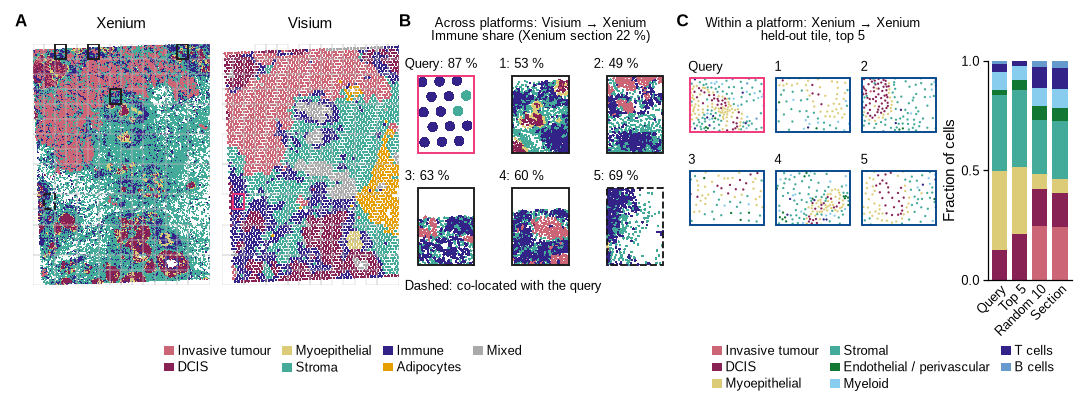

In [5]:
def legend_ab(fig):
    present = [c for c in classes if c in CLASS_COLORS]
    fig.legend(handles=[Patch(fc=CLASS_COLORS[c], ec="none", label=c) for c in present], loc="upper center",
               ncol=4, handlelength=0.8, columnspacing=0.9, handletextpad=0.3)


def legend_c(fig):
    fig.legend(handles=[Patch(fc=BREAST_COLORS[n], ec="none", label=n) for n in BREAST_NAMES], loc="upper center",
               ncol=3, handlelength=0.8, columnspacing=0.9, handletextpad=0.3)


fig = ps.panel(W_A + W_B, LEG_H); legend_ab(fig); ps.save_panel(fig, FIG, "legend_AB")
fig = ps.panel(W_C, LEG_H); legend_c(fig); ps.save_panel(fig, FIG, "legend_C")

page = ps.page(180, H + LEG_H)
panel_a(ps.place(page, "A", 0, 0, W_A, H))
panel_b(ps.place(page, "B", W_A + 1.0, 0, W_B, H, dx=-1.0))
panel_c(ps.place(page, "C", 180 - W_C, 0, W_C, H, dx=-2.0))
legend_ab(ps.place(page, None, 0, H, W_A + W_B, LEG_H))
legend_c(ps.place(page, None, 180 - W_C, H, W_C, LEG_H))
ps.save_figure(page, FIG)
plt.show()